# Task
Phishing email binary classification using BART-large-MNLI (zero-shot).

Follow the [reference project](https://github.com/salhabheba-cyber/AI-Phishing-Detector) README. Its implementation files were unavailable during preparation; labels and the binary decision rule below are explicit experiment choices, not a verified reproduction.

---


# Prerequisites

Use the Python version in `.python-version` and install dependencies from `requirements.txt`. The first model load downloads weights from Hugging Face.


In [1]:
from pathlib import Path
import re
import pandas as pd
import torch
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from transformers import pipeline
from skimpy import skim

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/backend").is_dir())
DATA_DIR = ROOT / "Training/Phishing_Detection/.data"


W1031 11:36:16.778000 99240 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


---

# Dataset
Download the [Kaggle phishing email dataset](https://www.kaggle.com/datasets/naserabdullahalam/phishing-email-dataset) and use the combined `phishing_email.csv` in `Training/Phishing_Detection/.data/`. It contains `text_combined` and binary `label` columns (0 = legitimate, 1 = phishing/spam).


### **Load** the dataset and **summarize**.


In [2]:
# Load and read dataset.
DATA_PATH = DATA_DIR / "phishing_email.csv"
TEXT_COLUMN = "text_combined"
LABEL_COLUMN = "label"
LABEL_MAP = {0: 0, 1: 1}

data = pd.read_csv(DATA_PATH)
assert {TEXT_COLUMN, LABEL_COLUMN} <= set(data.columns), "Expected text_combined and label columns."
assert data[LABEL_COLUMN].dropna().isin(LABEL_MAP).all(), "Expected binary labels 0 and 1."


# Summary.
skim(data)


╭──────────────────────────────────────────────── skimpy summary ─────────────────────────────────────────────────╮
│          Data Summary                Data Types                                                                 │
│ ┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┓ ┏━━━━━━━━━━━━━┳━━━━━━━┓                                                          │
│ ┃ dataframe         ┃ Values ┃ ┃ Column Type ┃ Count ┃                                                          │
│ ┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━┩ ┡━━━━━━━━━━━━━╇━━━━━━━┩                                                          │
│ │ Number of rows    │ 82486  │ │ string      │ 1     │                                                          │
│ │ Number of columns │ 2      │ │ int64       │ 1     │                                                          │
│ └───────────────────┴────────┘ └─────────────┴───────┘                                                          │
│                                                     number                                                      │
│ ┏━━━━━━━━━━━━━━━━━━━┳━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━┳━━━━━━━┳━━━━━━━┳━━━━━━━┳━━━━━━━━┳━━━━━━━━━┓  │
│ ┃ column_name       ┃ NA   ┃ NA %    ┃ mean    ┃ sd        ┃ p0   ┃ p25   ┃ p50   ┃ p75   ┃ p100   ┃ hist    ┃  │
│ ┡━━━━━━━━━━━━━━━━━━━╇━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━╇━━━━━━━╇━━━━━━━╇━━━━━━━╇━━━━━━━━╇━━━━━━━━━┩  │
│ │ label             │    0 │       0 │    0.52 │    0.4996 │    0 │     0 │     1 │     1 │      1 │ ▇    ▇  │  │
│ └───────────────────┴──────┴─────────┴─────────┴───────────┴──────┴───────┴───────┴───────┴────────┴─────────┘  │
│                                                     string                                                      │
│ ┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┓  │
│ ┃ column_name                  ┃ NA     ┃ NA %       ┃ words per row               ┃ total words             ┃  │
│ ┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━┩  │
│ │ text_combined                │      0 │          0 │                         160 │                13250579 │  │
│ └──────────────────────────────┴────────┴────────────┴─────────────────────────────┴─────────────────────────┘  │
╰────────────────────────────────────────────────────── End ──────────────────────────────────────────────────────╯

### **Drop** missing/blank emails and **deduplicate** samples.
Normalize whitespace while preserving email content. Reject conflicting labels before splitting.


In [3]:
# Drop samples with missing text or labels.
rows_before = len(data)
data_dropped = data.dropna(subset=[TEXT_COLUMN, LABEL_COLUMN]).copy()


# Normalize whitespace and remove blank emails.
data_dropped["text"] = data_dropped[TEXT_COLUMN].astype(str).map(
    lambda text: re.sub(r"\s+", " ", text).strip()
)
data_dropped["label"] = data_dropped[LABEL_COLUMN].map(LABEL_MAP)
data_dropped = data_dropped.loc[data_dropped["text"].ne("")]


# Reject conflicting labels, then deduplicate samples and reset the index.
assert data_dropped.groupby("text")["label"].nunique().max() == 1, "Resolve conflicting labels."
data_dropped = data_dropped.drop_duplicates("text")[["text", "label"]].reset_index(drop=True)
assert set(data_dropped["label"]) == {0, 1}


# Summary.
print(f"Removed {rows_before - len(data_dropped):,} missing, blank, or duplicate samples.")
skim(data_dropped)


Removed 409 missing, blank, or duplicate samples.


╭──────────────────────────────────────────────── skimpy summary ─────────────────────────────────────────────────╮
│          Data Summary                Data Types                                                                 │
│ ┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┓ ┏━━━━━━━━━━━━━┳━━━━━━━┓                                                          │
│ ┃ dataframe         ┃ Values ┃ ┃ Column Type ┃ Count ┃                                                          │
│ ┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━┩ ┡━━━━━━━━━━━━━╇━━━━━━━┩                                                          │
│ │ Number of rows    │ 82077  │ │ string      │ 1     │                                                          │
│ │ Number of columns │ 2      │ │ int64       │ 1     │                                                          │
│ └───────────────────┴────────┘ └─────────────┴───────┘                                                          │
│                                                     number                                                      │
│ ┏━━━━━━━━━━━━━━━━━━┳━━━━━━┳━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━┳━━━━━━━┳━━━━━━━┳━━━━━━━┳━━━━━━━━┳━━━━━━━━━┓  │
│ ┃ column_name      ┃ NA   ┃ NA %    ┃ mean     ┃ sd        ┃ p0   ┃ p25   ┃ p50   ┃ p75   ┃ p100   ┃ hist    ┃  │
│ ┡━━━━━━━━━━━━━━━━━━╇━━━━━━╇━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━╇━━━━━━━╇━━━━━━━╇━━━━━━━╇━━━━━━━━╇━━━━━━━━━┩  │
│ │ label            │    0 │       0 │    0.522 │    0.4995 │    0 │     0 │     1 │     1 │      1 │ ▇    ▇  │  │
│ └──────────────────┴──────┴─────────┴──────────┴───────────┴──────┴───────┴───────┴───────┴────────┴─────────┘  │
│                                                     string                                                      │
│ ┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┓  │
│ ┃ column_name               ┃ NA      ┃ NA %       ┃ words per row                ┃ total words              ┃  │
│ ┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━┩  │
│ │ text                      │       0 │          0 │                          160 │                 13191166 │  │
│ └───────────────────────────┴─────────┴────────────┴──────────────────────────────┴──────────────────────────┘  │
╰────────────────────────────────────────────────────── End ──────────────────────────────────────────────────────╯

### Split the dataset into Test, Train, and Eval.
Stratify to preserve class proportions. Test supports experimentation; eval is held out.


In [4]:
# Get the Train split. Hold out a split for Test and Eval.
train, holdout = train_test_split(
    data_dropped, train_size=0.7, random_state=123, stratify=data_dropped["label"]
)


# Get the Test and Eval splits from the holdout split.
test, eval_data = train_test_split(
    holdout, train_size=0.5, random_state=123, stratify=holdout["label"]
)


# Summary.
for name, frame in [("Train", train), ("Test", test), ("Eval", eval_data)]:
    print(f"{name} samples: {len(frame):,} --> {len(frame) / len(data_dropped):.2%}")


Train samples: 57,453 --> 70.00%
Test samples: 12,312 --> 15.00%
Eval samples: 12,312 --> 15.00%


# Preprocessing
The model tokenizer handles encoding. No vocabulary or scaler is fitted. Long emails are truncated to the model input limit.

# Model
Use the reference README’s BART model. Candidate labels below are experiment configuration.

In [5]:
MODEL_ID = "facebook/bart-large-mnli"
classifier = pipeline("zero-shot-classification", model=MODEL_ID, device=0 if torch.cuda.is_available() else -1)
LABELS = ["phishing email", "legitimate email"]

def predict(frame):
    results = classifier(frame["text"].tolist(), candidate_labels=LABELS, truncation=True, batch_size=4)
    return [int(result["labels"][0] == LABELS[0]) for result in results]


Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

# Training
Zero-shot classification does not train on this dataset. The train partition is reserved for future trainable models. No URL score boost or risk-band threshold is added without verified source behavior.

### Test a small development sample first.

In [6]:
test_sample = test.sample(n=min(20, len(test)), random_state=42)
test_predictions = predict(test_sample)
print(classification_report(test_sample["label"], test_predictions, labels=[0, 1], target_names=["legitimate", "phishing"], zero_division=0))


              precision    recall  f1-score   support

  legitimate       0.50      0.62      0.56         8
    phishing       0.70      0.58      0.64        12

    accuracy                           0.60        20
   macro avg       0.60      0.60      0.60        20
weighted avg       0.62      0.60      0.60        20



# Evaluation
After fixing configuration, evaluate the complete held-out eval split. This may be slow on CPU. Do not tune against these results.

              precision    recall  f1-score   support

  legitimate       0.48      0.69      0.57      5885
    phishing       0.52      0.30      0.38      6427

    accuracy                           0.49     12312
   macro avg       0.50      0.50      0.47     12312
weighted avg       0.50      0.49      0.47     12312



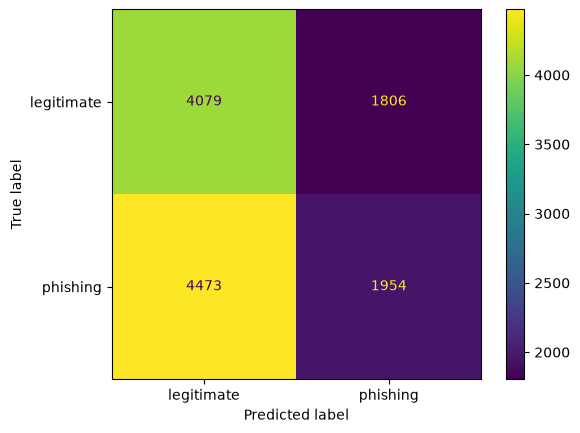

In [7]:
eval_predictions = predict(eval_data)
print(classification_report(eval_data["label"], eval_predictions, labels=[0, 1], target_names=["legitimate", "phishing"], zero_division=0))
ConfusionMatrixDisplay.from_predictions(eval_data["label"], eval_predictions, labels=[0, 1], display_labels=["legitimate", "phishing"])
